## Introdução

O **AGROvsClima** é um projeto de análise exploratória de dados que investiga a relação entre variáveis climáticas e o rendimento agrícola das culturas de soja e milho nos municípios de Cascavel, Toledo e Castro, no Paraná, durante o período de 2020 a 2022.

O objetivo é explorar como a precipitação acumulada e a temperatura média anual se relacionam com a produtividade agrícola, além de comparar a evolução do rendimento entre municípios, culturas e anos.

O projeto utiliza Python para tratamento e análise dos dados, Pandas para manipulação de tabelas, Matplotlib e Seaborn para visualização gráfica e SQLite com SQL para armazenamento e integração das informações. A análise busca demonstrar como ferramentas de dados podem auxiliar na identificação de tendências e padrões relacionados à agricultura e ao clima.

## Criação do Banco de Dados SQLite e Modelagem SQL



In [17]:

import requests
import pandas as pd
import numpy as np

# 1. Parâmetros e municípios de interesse
municipios = [
    {
        "nome": "Cascavel",
        "codigo_ibge": "4104808",
        "lat": -24.9578,
        "lon": -53.4597
    },
    {
        "nome": "Toledo",
        "codigo_ibge": "4127700",
        "lat": -24.7149,
        "lon": -53.7426
    },
    {
        "nome": "Castro",
        "codigo_ibge": "4104907",
        "lat": -24.7911,
        "lon": -50.0119
    }
]

anos = [2020, 2021, 2022]

# 2. Extração dos dados agrícolas do SIDRA
# Tabela 1612 | Classificação 81
# 2711 = Milho (em grão)
# 2713 = Soja (em grão)

print("Iniciando extração de dados agrícolas do SIDRA...")

dados_agricolas_lista = []
erros_consulta = []

for m in municipios:
    url = (
        "https://apisidra.ibge.gov.br/values/"
        f"t/1612/n6/{m['codigo_ibge']}/"
        "c81/2711,2713/"
        "p/2020,2021,2022/"
        "v/allxp"
    )

    try:
        resposta = requests.get(url, timeout=30)
        resposta.raise_for_status()

        dados_json = resposta.json()

        if len(dados_json) <= 1:
            erros_consulta.append(
                f"{m['nome']}: consulta sem registros."
            )
            continue

        for registro in dados_json[1:]:
            valor_original = registro.get("V")

            # Mantém valores ausentes como NaN,
            # sem transformá-los artificialmente em zero.
            valor = pd.to_numeric(
                valor_original, errors="coerce"
            )

            dados_agricolas_lista.append({
                "id_municipio_ibge": m["codigo_ibge"],
                "nome_municipio": m["nome"],
                "ano": int(registro["D3N"]),
                "cultura": registro["D2N"],
                "indicador": registro["D4N"],
                "unidade": registro["MN"],
                "valor": valor
            })

        print(f"{m['nome']}: consulta concluída.")

    except Exception as e:
        erros_consulta.append(f"{m['nome']}: {e}")
        print(f"Falha em {m['nome']}: {e}")

# 3. Criar a base final
dados_agricolas_municipais = pd.DataFrame(
    dados_agricolas_lista
)

if not dados_agricolas_municipais.empty:

    dados_agricolas_municipais = (
        dados_agricolas_municipais
        .drop_duplicates(
            subset=[
                "id_municipio_ibge",
                "ano",
                "cultura",
                "indicador"
            ]
        )
        .reset_index(drop=True)
    )

    # Criar uma tabela com um indicador por coluna.
    dados_agricolas_resumo = (
        dados_agricolas_municipais
        .pivot_table(
            index=[
                "id_municipio_ibge",
                "nome_municipio",
                "ano",
                "cultura"
            ],
            columns="indicador",
            values="valor",
            aggfunc="first"
        )
        .reset_index()
    )

    dados_agricolas_resumo.columns.name = None

    print("\n--- Amostra dos dados agrícolas ---")
    display(dados_agricolas_municipais.head(10))

    print("\n--- Base resumida para os gráficos ---")
    display(dados_agricolas_resumo.head(10))

else:
    print("Nenhum dado agrícola foi obtido.")

# 4. Relatório de falhas: sem fallback de dados simulados
if erros_consulta:
    print("\n--- Consultas que precisam ser verificadas ---")
    for erro in erros_consulta:
        print("-", erro)
else:
    print("\nTodas as consultas foram concluídas sem erros.")


Iniciando extração de dados agrícolas do SIDRA...
Cascavel: consulta concluída.
Toledo: consulta concluída.
Castro: consulta concluída.

--- Amostra dos dados agrícolas ---


,id_municipio_ibge,nome_municipio,ano,cultura,indicador,unidade,valor
0,4104808,Cascavel,2020,Milho (em grão),Área plantada,Hectares,42000
1,4104808,Cascavel,2020,Milho (em grão),Área colhida,Hectares,42000
2,4104808,Cascavel,2020,Milho (em grão),Quantidade produzida,Toneladas,275132
3,4104808,Cascavel,2020,Milho (em grão),Rendimento médio da produção,Quilogramas por Hectare,6551
4,4104808,Cascavel,2020,Milho (em grão),Valor da produção,Mil Reais,215428
5,4104808,Cascavel,2021,Milho (em grão),Área plantada,Hectares,62200
6,4104808,Cascavel,2021,Milho (em grão),Área colhida,Hectares,62200
7,4104808,Cascavel,2021,Milho (em grão),Quantidade produzida,Toneladas,300000
8,4104808,Cascavel,2021,Milho (em grão),Rendimento médio da produção,Quilogramas por Hectare,4823
9,4104808,Cascavel,2021,Milho (em grão),Valor da produção,Mil Reais,360706



--- Base resumida para os gráficos ---


,id_municipio_ibge,nome_municipio,ano,cultura,Quantidade produzida,Rendimento médio da produção,Valor da produção,Área colhida,Área plantada
0,4104808,Cascavel,2020,Milho (em grão),275132,6551,215428,42000,42000
1,4104808,Cascavel,2020,Soja (em grão),423599,4119,741298,102830,102830
2,4104808,Cascavel,2021,Milho (em grão),300000,4823,360706,62200,62200
3,4104808,Cascavel,2021,Soja (em grão),300000,3464,737688,86600,86600
4,4104808,Cascavel,2022,Milho (em grão),279000,4486,383139,62200,62200
5,4104808,Cascavel,2022,Soja (em grão),260000,3002,766740,86600,86600
6,4104907,Castro,2020,Milho (em grão),102700,10480,61189,9800,9800
7,4104907,Castro,2020,Soja (em grão),265300,4050,340587,65500,65500
8,4104907,Castro,2021,Milho (em grão),90766,7714,70714,11767,11767
9,4104907,Castro,2021,Soja (em grão),231500,3700,299793,62565,62565



Todas as consultas foram concluídas sem erros.


In [19]:
import sqlite3
import pandas as pd

# 1. Conectar ao banco SQLite
conexao = sqlite3.connect("dados_agricultura_clima.db")

try:
    # 2. Salvar as bases no SQLite
    dados_agricolas_resumo.to_sql(
        "dados_agricolas_resumo",
        conexao,
        if_exists="replace",
        index=False
    )

    dados_climaticos_municipais.to_sql(
        "dados_climaticos_municipais",
        conexao,
        if_exists="replace",
        index=False
    )

    print("Tabelas carregadas no SQLite com sucesso!")

    # 3. Agregar os dados climáticos por município e ano
    query_sql = """
    WITH clima_anual AS (
        SELECT
            id_municipio_ibge,
            nome_municipio,
            ano,
            AVG(temperatura_media_c) AS temperatura_media_anual,
            SUM(precipitacao_acumulada_mm) AS precipitacao_acumulada_anual
        FROM dados_climaticos_municipais
        GROUP BY
            id_municipio_ibge,
            nome_municipio,
            ano
    )

    SELECT
        agri.id_municipio_ibge,
        agri.nome_municipio,
        agri.ano,
        agri.cultura,

        agri."Área plantada" AS area_plantada_ha,
        agri."Área colhida" AS area_colhida_ha,
        agri."Quantidade produzida" AS quantidade_produzida_t,
        agri."Rendimento médio da produção" AS rendimento_medio_kgha,
        agri."Valor da produção" AS valor_producao_mil_reais,

        clima.temperatura_media_anual,
        clima.precipitacao_acumulada_anual

    FROM dados_agricolas_resumo AS agri

    INNER JOIN clima_anual AS clima
        ON agri.id_municipio_ibge = clima.id_municipio_ibge
        AND agri.ano = clima.ano

    ORDER BY
        agri.nome_municipio,
        agri.cultura,
        agri.ano
    """

    # 4. Executar a consulta
    df_analise = pd.read_sql_query(query_sql, conexao)

finally:
    # 5. Fechar a conexão mesmo se ocorrer algum erro
    conexao.close()

print("Conexão com o banco de dados fechada.")

# 6. Conferir os resultados
print("\n--- Primeiras linhas de df_analise ---")
display(df_analise.head(10))

print("\n--- Informações de df_analise ---")
df_analise.info()

print("\n--- Quantidade de registros por município, cultura e ano ---")
display(
    df_analise.groupby(
        ["nome_municipio", "cultura", "ano"]
    ).size()
)


Tabelas carregadas no SQLite com sucesso!
Conexão com o banco de dados fechada.

--- Primeiras linhas de df_analise ---


,id_municipio_ibge,nome_municipio,ano,cultura,area_plantada_ha,area_colhida_ha,quantidade_produzida_t,rendimento_medio_kgha,valor_producao_mil_reais,temperatura_media_anual,precipitacao_acumulada_anual
0,4104808,Cascavel,2020,Milho (em grão),42000,42000,275132,6551,215428,21.615219,1331.99
1,4104808,Cascavel,2021,Milho (em grão),62200,62200,300000,4823,360706,21.368603,1186.41
2,4104808,Cascavel,2022,Milho (em grão),62200,62200,279000,4486,383139,20.139918,1920.75
3,4104808,Cascavel,2020,Soja (em grão),102830,102830,423599,4119,741298,21.615219,1331.99
4,4104808,Cascavel,2021,Soja (em grão),86600,86600,300000,3464,737688,21.368603,1186.41
5,4104808,Cascavel,2022,Soja (em grão),86600,86600,260000,3002,766740,20.139918,1920.75
6,4104907,Castro,2020,Milho (em grão),9800,9800,102700,10480,61189,18.897049,1106.47
7,4104907,Castro,2021,Milho (em grão),11767,11767,90766,7714,70714,18.492767,1015.28
8,4104907,Castro,2022,Milho (em grão),11400,11400,107000,9386,113420,17.869178,1533.86
9,4104907,Castro,2020,Soja (em grão),65500,65500,265300,4050,340587,18.897049,1106.47



--- Informações de df_analise ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id_municipio_ibge             18 non-null     object 
 1   nome_municipio                18 non-null     object 
 2   ano                           18 non-null     int64  
 3   cultura                       18 non-null     object 
 4   area_plantada_ha              18 non-null     int64  
 5   area_colhida_ha               18 non-null     int64  
 6   quantidade_produzida_t        18 non-null     int64  
 7   rendimento_medio_kgha         18 non-null     int64  
 8   valor_producao_mil_reais      18 non-null     int64  
 9   temperatura_media_anual       18 non-null     float64
 10  precipitacao_acumulada_anual  18 non-null     float64
dtypes: float64(2), int64(6), object(3)
memory usage: 1.7+ KB

--- Quantidade de registros por 

nome_municipio  cultura          ano 
Cascavel        Milho (em grão)  2020    1
                                 2021    1
                                 2022    1
                Soja (em grão)   2020    1
                                 2021    1
                                 2022    1
Castro          Milho (em grão)  2020    1
                                 2021    1
                                 2022    1
                Soja (em grão)   2020    1
                                 2021    1
                                 2022    1
Toledo          Milho (em grão)  2020    1
                                 2021    1
                                 2022    1
                Soja (em grão)   2020    1
                                 2021    1
                                 2022    1
dtype: int64

## Análise Estatística e Visualização de Dados


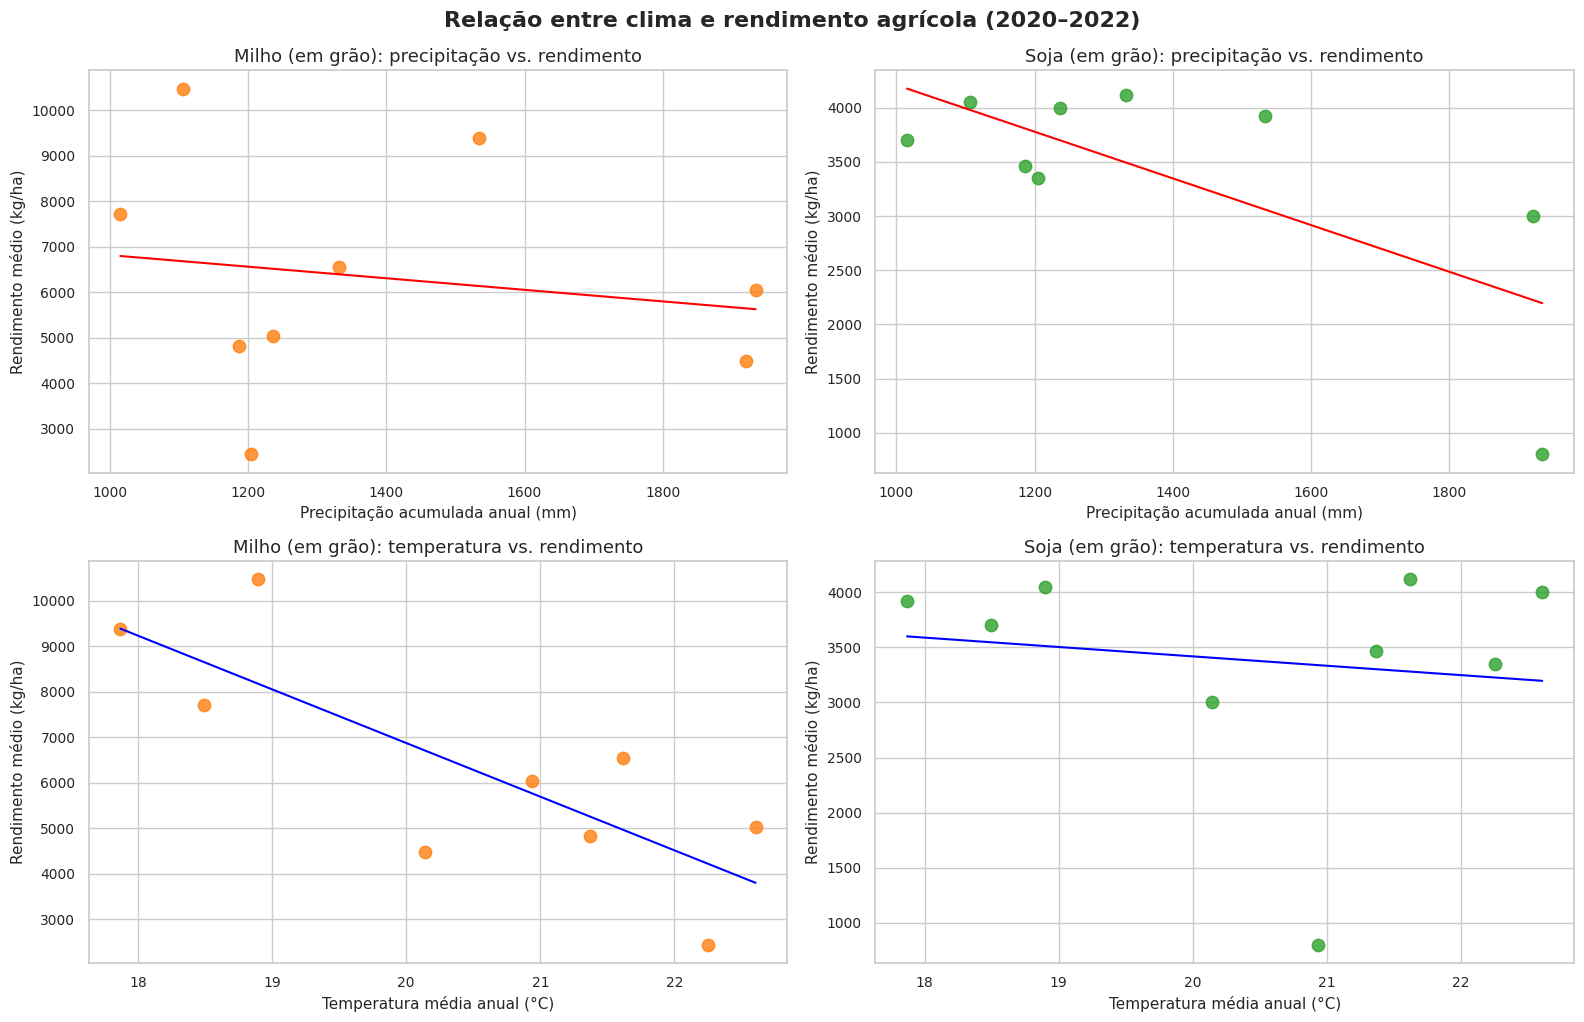

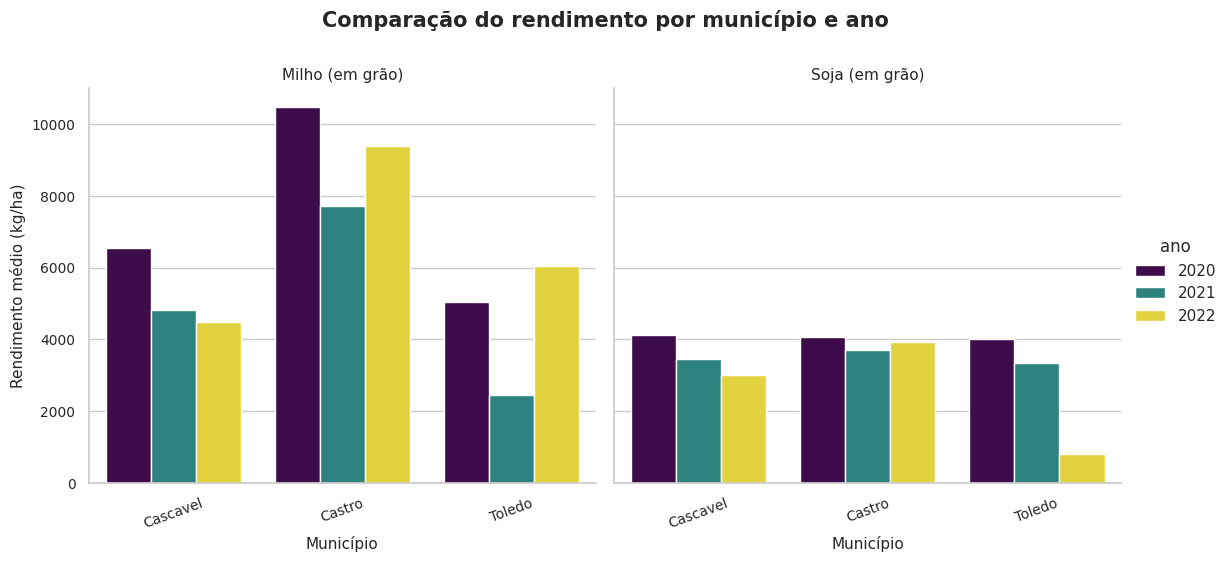

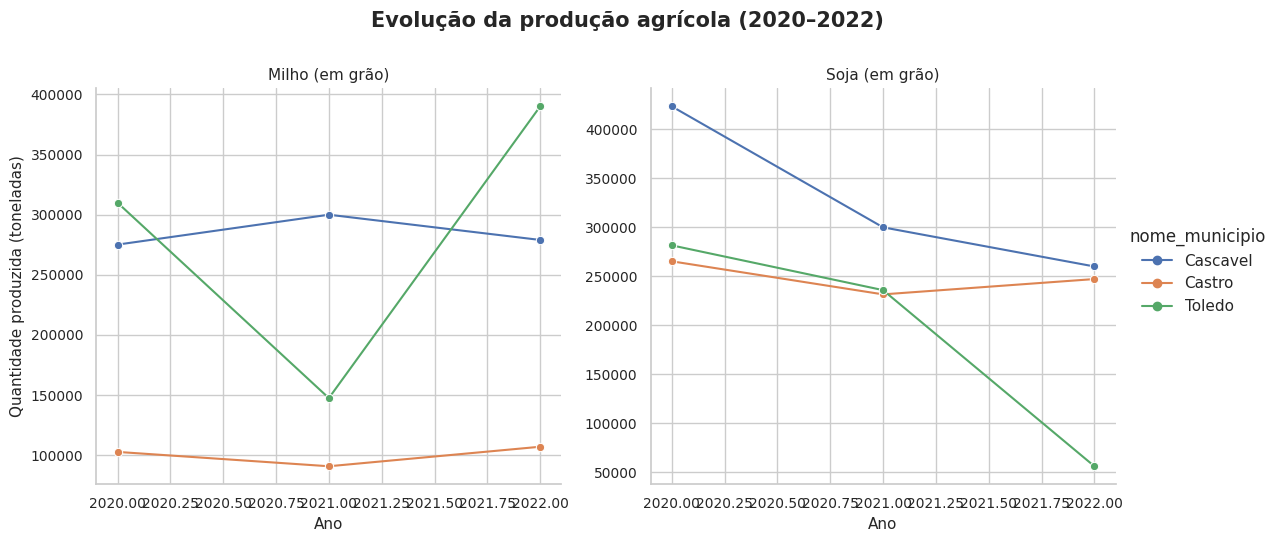

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Configuração visual
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 10)
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# Usar somente culturas presentes na base
culturas = sorted(df_analise["cultura"].dropna().unique())

cores = {
    "Soja (em grão)": "#2ca02c",
    "Milho (em grão)": "#ff7f0e"
}

# Criar uma cópia para não alterar a base original
df_graficos = df_analise.copy()

# Garantir que as colunas numéricas estejam no formato correto
colunas_numericas = [
    "rendimento_medio_kgha",
    "precipitacao_acumulada_anual",
    "temperatura_media_anual",
    "quantidade_produzida_t"
]

for coluna in colunas_numericas:
    if coluna in df_graficos.columns:
        df_graficos[coluna] = pd.to_numeric(
            df_graficos[coluna], errors="coerce"
        )

# 2. Dispersão: clima versus rendimento
fig, axes = plt.subplots(2, len(culturas), figsize=(8 * len(culturas), 10))

axes = np.array(axes).reshape(2, -1)

for i, cultura in enumerate(culturas):
    df_cult = df_graficos[
        df_graficos["cultura"] == cultura
    ]

    cor = cores.get(cultura, "gray")

    # Precipitação versus rendimento
    dados_prec = df_cult.dropna(
        subset=[
            "precipitacao_acumulada_anual",
            "rendimento_medio_kgha"
        ]
    )

    sns.regplot(
        data=dados_prec,
        x="precipitacao_acumulada_anual",
        y="rendimento_medio_kgha",
        ax=axes[0, i],
        color=cor,
        scatter_kws={"s": 80, "alpha": 0.8},
        line_kws={"color": "red", "linewidth": 1.5},
        ci=None
    )

    axes[0, i].set_title(
        f"{cultura}: precipitação vs. rendimento"
    )
    axes[0, i].set_xlabel("Precipitação acumulada anual (mm)")
    axes[0, i].set_ylabel("Rendimento médio (kg/ha)")

    # Temperatura versus rendimento
    dados_temp = df_cult.dropna(
        subset=[
            "temperatura_media_anual",
            "rendimento_medio_kgha"
        ]
    )

    sns.regplot(
        data=dados_temp,
        x="temperatura_media_anual",
        y="rendimento_medio_kgha",
        ax=axes[1, i],
        color=cor,
        scatter_kws={"s": 80, "alpha": 0.8},
        line_kws={"color": "blue", "linewidth": 1.5},
        ci=None
    )

    axes[1, i].set_title(
        f"{cultura}: temperatura vs. rendimento"
    )
    axes[1, i].set_xlabel("Temperatura média anual (°C)")
    axes[1, i].set_ylabel("Rendimento médio (kg/ha)")

plt.tight_layout()
fig.suptitle(
    "Relação entre clima e rendimento agrícola (2020–2022)",
    y=1.02,
    fontsize=16,
    fontweight="bold"
)
plt.show()


# 3. Comparação do rendimento por município, ano e cultura
g = sns.catplot(
    data=df_graficos.dropna(subset=["rendimento_medio_kgha"]),
    x="nome_municipio",
    y="rendimento_medio_kgha",
    hue="ano",
    col="cultura",
    kind="bar",
    palette="viridis",
    height=5,
    aspect=1.15
)

g.set_axis_labels("Município", "Rendimento médio (kg/ha)")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=20)

g.figure.suptitle(
    "Comparação do rendimento por município e ano",
    y=1.08,
    fontsize=15,
    fontweight="bold"
)
plt.show()


# 4. Evolução da quantidade produzida por município e cultura
g = sns.relplot(
    data=df_graficos.dropna(subset=["quantidade_produzida_t"]),
    x="ano",
    y="quantidade_produzida_t",
    hue="nome_municipio",
    col="cultura",
    kind="line",
    marker="o",
    facet_kws={"sharey": False},
    height=5,
    aspect=1.15
)

g.set_axis_labels("Ano", "Quantidade produzida (toneladas)")
g.set_titles("{col_name}")

g.figure.suptitle(
    "Evolução da produção agrícola (2020–2022)",
    y=1.08,
    fontsize=15,
    fontweight="bold"
)
plt.show()


## Conclusão

A análise do projeto **AGROvsClima** permitiu comparar a produção agrícola de soja e milho nos municípios de Cascavel, Toledo e Castro, no Paraná, entre 2020 e 2022, relacionando os indicadores de produtividade com as condições climáticas anuais.

Os resultados mostram que o rendimento agrícola variou conforme o município, a cultura e o ano analisado. Em Cascavel, por exemplo, houve redução do rendimento médio da soja e do milho ao longo do período observado. Já em Castro, o milho apresentou queda de rendimento em 2021, seguida de recuperação em 2022. Essas diferenças demonstram a importância de analisar cada cultura e região individualmente, em vez de considerar um comportamento único para toda a produção agrícola.

A comparação com os dados climáticos permitiu explorar possíveis relações entre a precipitação, a temperatura média e o rendimento das culturas. Entretanto, os resultados não permitem afirmar que as variações climáticas foram as únicas responsáveis pelas mudanças na produtividade, pois outros fatores, como manejo agrícola, condições do solo e tecnologias utilizadas, também podem influenciar a produção.

Conclui-se que a integração de dados agrícolas e climáticos possibilita identificar tendências, comparar resultados entre municípios e levantar hipóteses para investigações futuras. O projeto também demonstrou a aplicação prática de Python, Pandas, SQL, SQLite, Matplotlib e Seaborn na coleta, organização, integração e visualização de dados, contribuindo para o desenvolvimento de habilidades em análise exploratória de dados.
